<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/Assignment8/Homework_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# SJSU ID ending in 2738 — reproducibility seed (same as HW6)
SID4 = 2738
SEED = SID4

import os, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('SEED:', SEED)
T = 100
BATCH_SIZE = 128
EPOCHS = 50
LR = 1e-3
os.makedirs('hw8_outputs', exist_ok=True)


Device: cuda
SEED: 2738


a. Forward diffusion

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 482kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.5MB/s]


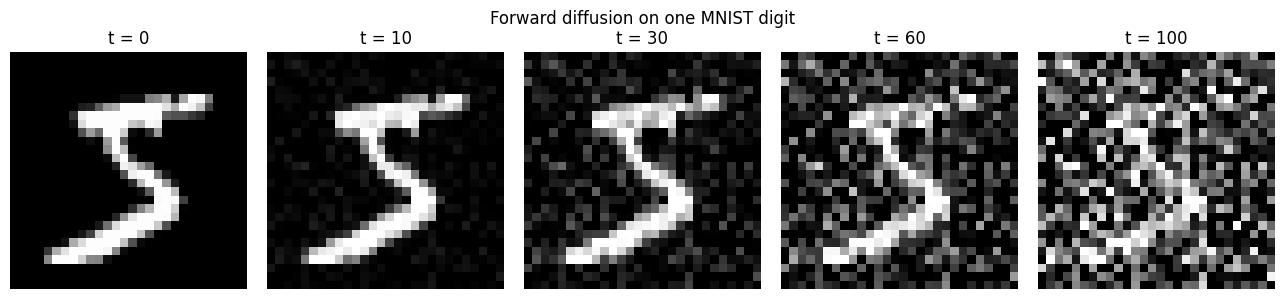

Final signal retention: alpha_bar[T] = 0.363563
Final noise fraction: 1 - alpha_bar[T] = 0.636437


In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x * 2 - 1)])
train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=(device.type == 'cuda'))
betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cat([torch.ones(1, device=device), torch.cumprod(alphas, dim=0)]) # index 0..T

def forward_diffusion(x0, t, noise=None):
    """x0: (B,1,28,28); t: (B,) integer in [0,T]."""
    if noise is None: noise = torch.randn_like(x0)
    a = alpha_bars[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1-a).sqrt() * noise, noise

sample, _ = train_data[0]
x0 = sample.unsqueeze(0).to(device)
steps = [0, 10, 30, 60, 100]
fixed_noise = torch.randn_like(x0)
fig, axes = plt.subplots(1, len(steps), figsize=(13, 3))
for ax, step in zip(axes, steps):
    xt, _ = forward_diffusion(x0, torch.tensor([step], device=device), fixed_noise)
    ax.imshow(xt[0,0].cpu().clamp(-1,1), cmap='gray', vmin=-1, vmax=1)
    ax.set_title(f't = {step}'); ax.axis('off')
plt.suptitle('Forward diffusion on one MNIST digit')
plt.tight_layout(); plt.savefig('hw8_outputs/forward_diffusion.png', dpi=160); plt.show()
print(f'Final signal retention: alpha_bar[T] = {alpha_bars[T].item():.6f}')
print(f'Final noise fraction: 1 - alpha_bar[T] = {1-alpha_bars[T].item():.6f}')


b. Train a mini DDPM

Trainable parameters: 559489


Epoch 1/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 01/50 | mean MSE = 0.119641


Epoch 2/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 02/50 | mean MSE = 0.072899


...

Epoch 48/50 | mean MSE = 0.052903


Epoch 49/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 49/50 | mean MSE = 0.053140


Epoch 50/50:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 50/50 | mean MSE = 0.053040


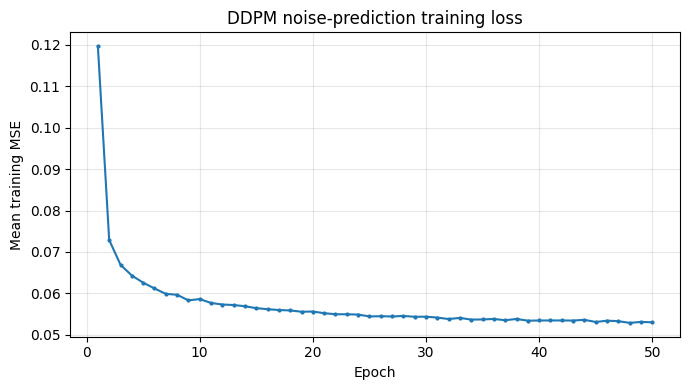

In [3]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)

    def forward(self, x, temb):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time_proj(temb)[:, :, None, None]
        return F.silu(self.norm2(self.conv2(h)))

class NoisePredictor(nn.Module):
    """Timestep-conditioned U-Net: 28 -> 14 -> 7 -> 14 -> 28."""
    def __init__(self, hidden=32, time_dim=128):
        super().__init__()
        self.time_embed = nn.Sequential(
            nn.Embedding(T + 1, time_dim),
            nn.Linear(time_dim, time_dim), nn.SiLU(),
            nn.Linear(time_dim, time_dim))
        self.enc1 = ConvBlock(1, hidden, time_dim)
        self.enc2 = ConvBlock(hidden, hidden * 2, time_dim)
        self.mid = ConvBlock(hidden * 2, hidden * 4, time_dim)
        self.dec2 = ConvBlock(hidden * 4 + hidden * 2, hidden * 2, time_dim)
        self.dec1 = ConvBlock(hidden * 2 + hidden, hidden, time_dim)
        self.out = nn.Conv2d(hidden, 1, 1)

    def forward(self, x, t):
        temb = self.time_embed(t)
        skip1 = self.enc1(x, temb)
        skip2 = self.enc2(F.avg_pool2d(skip1, 2), temb)
        h = self.mid(F.avg_pool2d(skip2, 2), temb)
        h = F.interpolate(h, size=skip2.shape[-2:], mode='nearest')
        h = self.dec2(torch.cat([h, skip2], dim=1), temb)
        h = F.interpolate(h, size=skip1.shape[-2:], mode='nearest')
        h = self.dec1(torch.cat([h, skip1], dim=1), temb)
        return self.out(h)

model = NoisePredictor().to(device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
assert model(torch.randn(2,1,28,28,device=device), torch.tensor([1,100],device=device)).shape == (2,1,28,28)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
loss_history = []

for epoch in range(EPOCHS):
    model.train(); running = 0.0; count = 0
    for images, _ in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False):
        images = images.to(device, non_blocking=True)
        t = torch.randint(1, T+1, (images.size(0),), device=device)
        noisy, eps = forward_diffusion(images, t)
        predicted = model(noisy, t)
        loss = F.mse_loss(predicted, eps)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        running += loss.item() * images.size(0); count += images.size(0)
    avg = running / count
    loss_history.append(avg)
    print(f'Epoch {epoch+1:02d}/{EPOCHS} | mean MSE = {avg:.6f}')
    if (epoch+1) % 10 == 0:
        torch.save({'model':model.state_dict(), 'epoch':epoch+1,
                    'loss_history':loss_history}, 'hw8_outputs/ddpm_checkpoint.pt')

plt.figure(figsize=(7,4))
plt.plot(range(1,len(loss_history)+1), loss_history, marker='o', markersize=2)
plt.xlabel('Epoch'); plt.ylabel('Mean training MSE'); plt.title('DDPM noise-prediction training loss')
plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('hw8_outputs/training_loss.png', dpi=160); plt.show()

c. DDPM sampling

DDPM 100 steps: 0.29 seconds


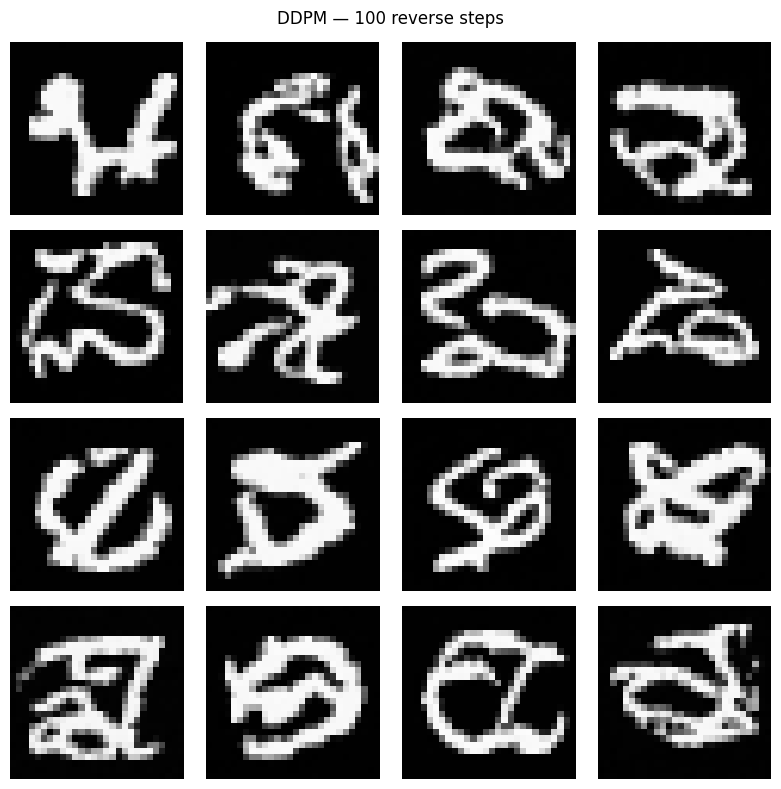

In [4]:
@torch.no_grad()
def sample_ddpm(model, n=16, initial_noise=None):
    model.eval()
    x = torch.randn(n,1,28,28,device=device) if initial_noise is None else initial_noise.clone().to(device)
    for t in range(T, 0, -1):
        time_ids = torch.full((x.size(0),), t, device=device, dtype=torch.long)
        eps = model(x, time_ids)
        beta = betas[t-1]; alpha = alphas[t-1]
        ab = alpha_bars[t]; ab_prev = alpha_bars[t-1]
        mean = (x - beta / torch.sqrt(1-ab) * eps) / torch.sqrt(alpha)
        if t > 1:
            posterior_var = beta * (1-ab_prev) / (1-ab)
            x = mean + posterior_var.sqrt() * torch.randn_like(x)
        else:
            x = mean
    return x

def show_grid(images, title, path, cols=4):
    images = images.detach().cpu().clamp(-1,1)
    rows = int(np.ceil(len(images)/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2, rows*2))
    for i, ax in enumerate(np.array(axes).reshape(-1)):
        if i < len(images): ax.imshow(images[i,0], cmap='gray', vmin=-1, vmax=1)
        ax.axis('off')
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(path, dpi=160); plt.show()

initial_noise = torch.randn(16,1,28,28,device=device)
start = time.perf_counter()
ddpm_images = sample_ddpm(model, initial_noise=initial_noise)
if device.type == 'cuda': torch.cuda.synchronize()
ddpm_seconds = time.perf_counter() - start
print(f'DDPM 100 steps: {ddpm_seconds:.2f} seconds')
show_grid(ddpm_images, 'DDPM — 100 reverse steps', 'hw8_outputs/ddpm_100.png')

d. DDIM sampling

DDIM 50 steps: 0.15 seconds
DDIM 20 steps: 0.05 seconds
Network evaluations: DDPM=100, DDIM-50=50, DDIM-20=20


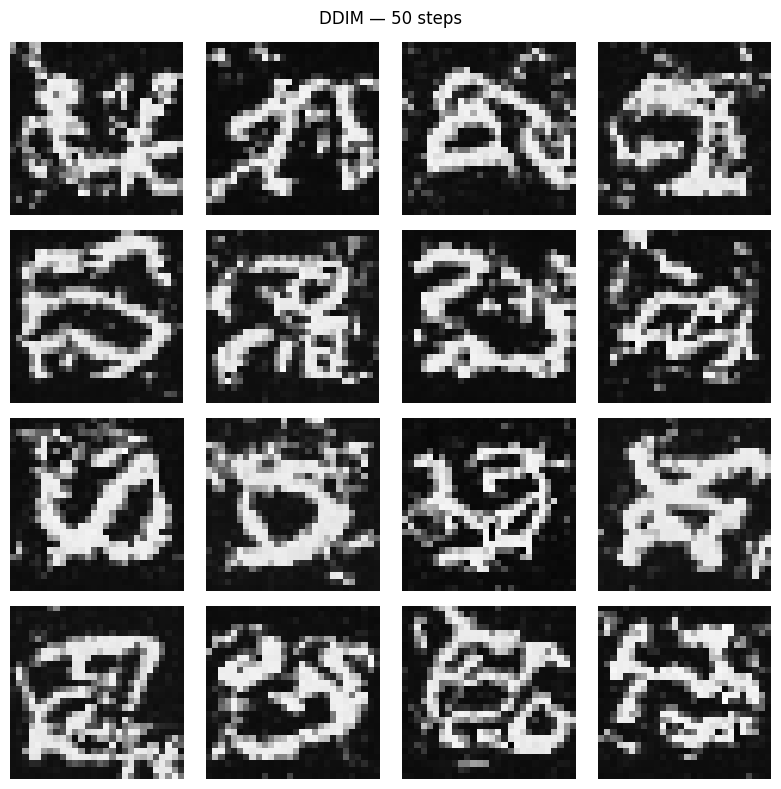

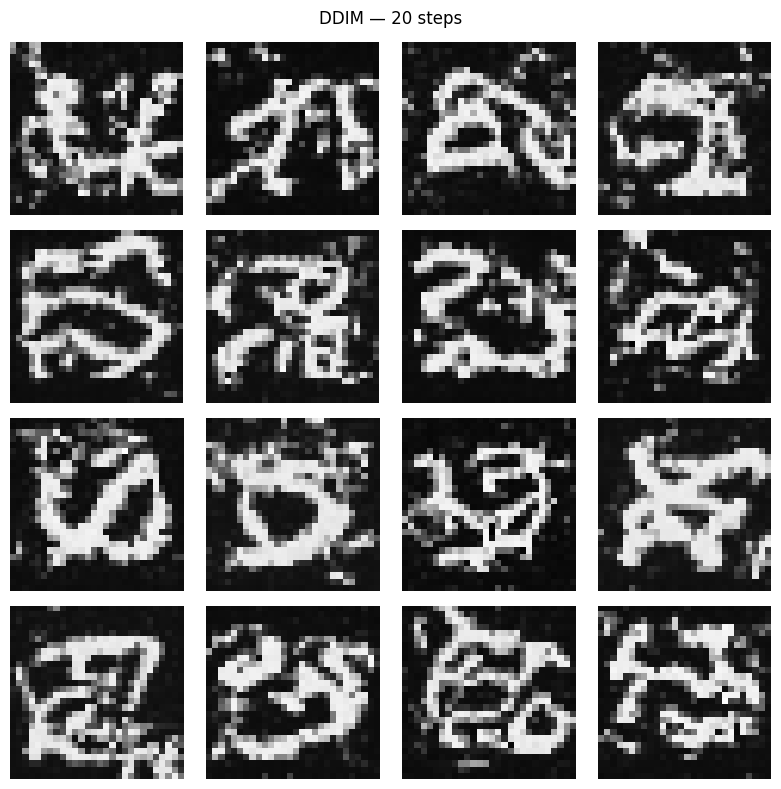

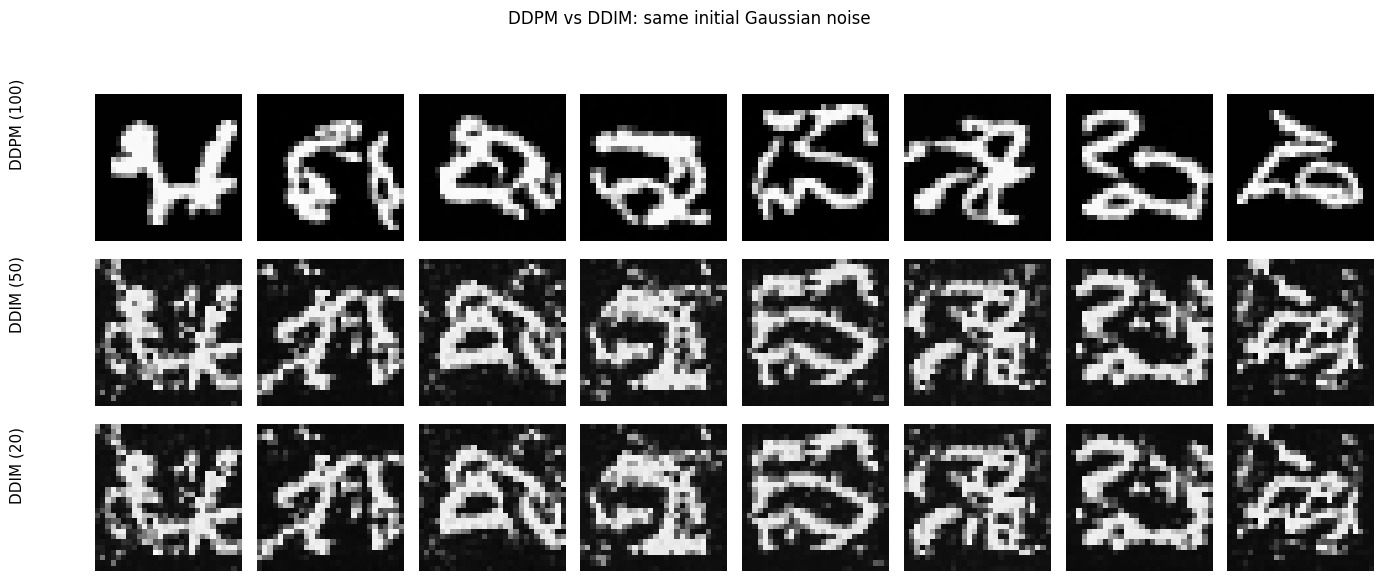

In [5]:
@torch.no_grad()
def sample_ddim(model, steps=50, initial_noise=None, n=16):
    assert 1 <= steps <= T
    model.eval()
    x = torch.randn(n,1,28,28,device=device) if initial_noise is None else initial_noise.clone().to(device)
    # Integer timesteps, from T down to 1, followed by clean t=0.
    times = np.linspace(1, T, steps, dtype=int)[::-1].tolist()
    assert len(times) == steps and len(set(times)) == steps
    for i, t in enumerate(times):
        prev_t = times[i+1] if i+1 < len(times) else 0
        ids = torch.full((x.size(0),), t, device=device, dtype=torch.long)
        eps = model(x, ids)
        ab_t, ab_prev = alpha_bars[t], alpha_bars[prev_t]
        x0_hat = (x - torch.sqrt(1-ab_t)*eps) / torch.sqrt(ab_t)
        x = torch.sqrt(ab_prev)*x0_hat + torch.sqrt(1-ab_prev)*eps
    return x

if device.type == 'cuda': torch.cuda.synchronize()
start = time.perf_counter()
ddim_50 = sample_ddim(model, 50, initial_noise)
if device.type == 'cuda': torch.cuda.synchronize()
ddim50_seconds = time.perf_counter() - start
start = time.perf_counter()
ddim_20 = sample_ddim(model, 20, initial_noise)
if device.type == 'cuda': torch.cuda.synchronize()
ddim20_seconds = time.perf_counter() - start
print(f'DDIM 50 steps: {ddim50_seconds:.2f} seconds')
print(f'DDIM 20 steps: {ddim20_seconds:.2f} seconds')
print('Network evaluations: DDPM=100, DDIM-50=50, DDIM-20=20')
show_grid(ddim_50, 'DDIM — 50 steps', 'hw8_outputs/ddim_50.png')
show_grid(ddim_20, 'DDIM — 20 steps', 'hw8_outputs/ddim_20.png')

fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for row, (name, imgs) in enumerate([('DDPM (100)', ddpm_images), ('DDIM (50)', ddim_50), ('DDIM (20)', ddim_20)]):
    for col in range(8):
        axes[row,col].imshow(imgs[col,0].detach().cpu().clamp(-1,1), cmap='gray', vmin=-1, vmax=1)
        axes[row,col].axis('off')
    fig.text(0.015, 0.79-row*0.285, name, va='center', rotation=90, fontsize=11)
fig.suptitle('DDPM vs DDIM: same initial Gaussian noise')
plt.tight_layout(rect=[0.065, 0, 1, 0.94]); plt.savefig('hw8_outputs/comparison.png', dpi=160); plt.show()

Additional experiment — Config B (stronger noise schedule)

**Config A** above follows the assignment exactly: $T=100$, $\beta$ from 0.0001 to 0.02. Its $\bar\alpha_T\approx0.364$, so the terminal training input still contains a strong signal, unlike the pure Gaussian used to start sampling.

**Config B** is a clearly labeled *additional experiment*, not a replacement for the required schedule: $\beta$ from 0.001 to 0.2, with the same architecture and 50 training epochs. It brings $\bar\alpha_T$ close to zero, reducing the terminal train–sample mismatch. All three sampling methods are repeated with identical starting noise. Better results are plausible, **not guaranteed**; inspect the actual grids.


Config A alpha_bar[T]: 0.36356321
Config B alpha_bar[T]: 0.00002039


Config B epoch 1/50:   0%|          | 0/469 [00:00<?, ?it/s]

Config B epoch 01/50: MSE=0.06094


Config B epoch 2/50:   0%|          | 0/469 [00:00<?, ?it/s]

Config B epoch 02/50: MSE=0.03145


...

Config B epoch 48/50: MSE=0.02163


Config B epoch 49/50:   0%|          | 0/469 [00:00<?, ?it/s]

Config B epoch 49/50: MSE=0.02148


Config B epoch 50/50:   0%|          | 0/469 [00:00<?, ?it/s]

Config B epoch 50/50: MSE=0.02154


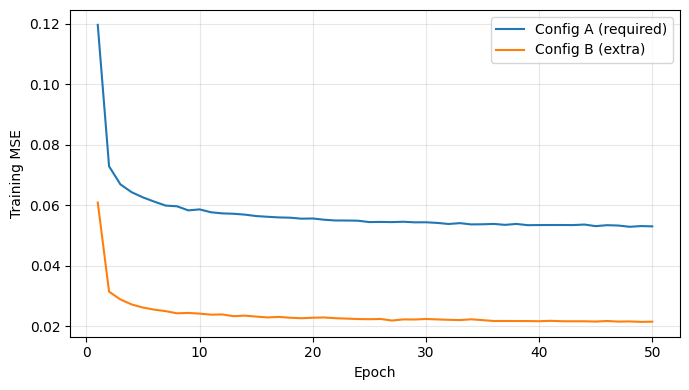

Config B timings: DDPM-100=0.267s; DDIM-50=0.132s; DDIM-20=0.055s


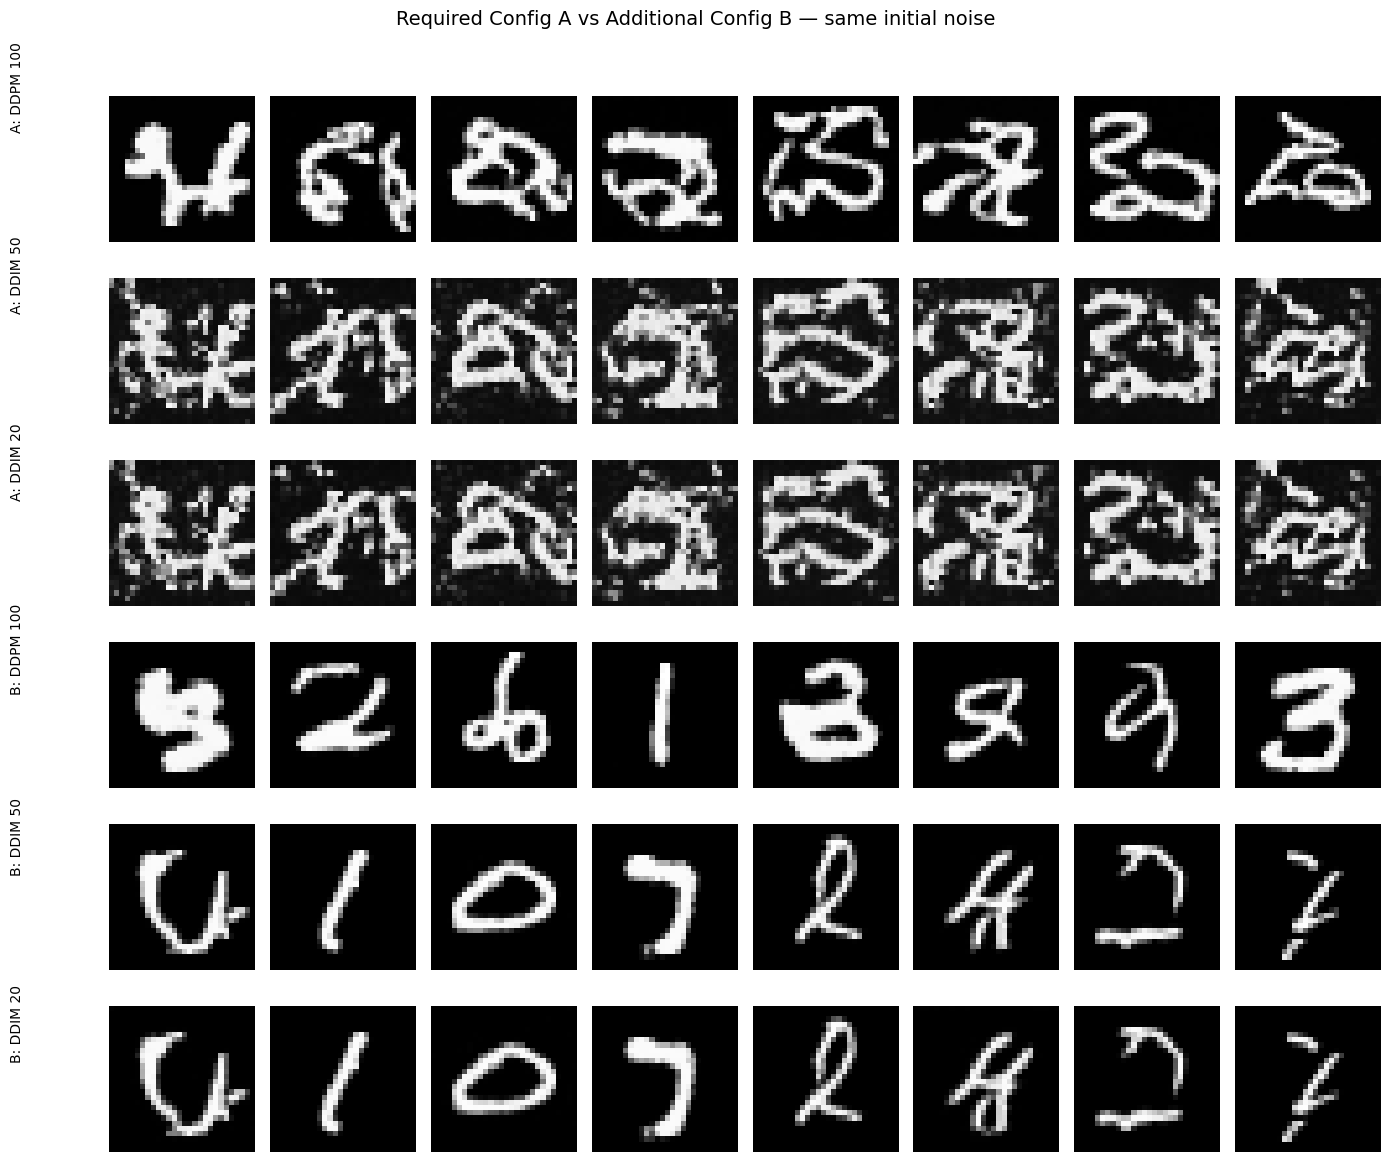

In [6]:
# Config B — extra experiment; preserve Config A results and checkpoint
betas_A, alphas_A, alpha_bars_A = betas, alphas, alpha_bars
model_A = model
betas = torch.linspace(0.001, 0.2, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cat([torch.ones(1, device=device), torch.cumprod(alphas, dim=0)])
print(f"Config A alpha_bar[T]: {alpha_bars_A[T].item():.8f}")
print(f"Config B alpha_bar[T]: {alpha_bars[T].item():.8f}")

# forward_diffusion, sample_ddpm, and sample_ddim read the currently active schedule
model_B = NoisePredictor().to(device)
optimizer_B = torch.optim.Adam(model_B.parameters(), lr=LR)
loss_history_B = []
for epoch in range(EPOCHS):
    model_B.train()
    total, count = 0.0, 0
    for images, _ in tqdm(train_loader, desc=f'Config B epoch {epoch+1}/{EPOCHS}', leave=False):
        images = images.to(device, non_blocking=True)
        t = torch.randint(1, T+1, (images.size(0),), device=device)
        xt, eps = forward_diffusion(images, t)
        loss = F.mse_loss(model_B(xt, t), eps)
        optimizer_B.zero_grad(set_to_none=True)
        loss.backward()
        optimizer_B.step()
        total += loss.item()*images.size(0)
        count += images.size(0)
    loss_history_B.append(total/count)
    print(f'Config B epoch {epoch+1:02d}/{EPOCHS}: MSE={loss_history_B[-1]:.5f}')
    if (epoch+1)%10 == 0:
        torch.save({'model': model_B.state_dict(), 'epoch':epoch+1,
                    'loss_history':loss_history_B, 'beta_start':0.001,
                    'beta_end':0.2}, 'hw8_outputs/config_B_checkpoint.pt')

plt.figure(figsize=(7,4))
plt.plot(range(1,EPOCHS+1), loss_history, label='Config A (required)')
plt.plot(range(1,EPOCHS+1), loss_history_B, label='Config B (extra)')
plt.xlabel('Epoch'); plt.ylabel('Training MSE'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('hw8_outputs/loss_comparison.png',dpi=160); plt.show()

# GPU synchronization before AND after each measurement
@torch.no_grad()
def timed_sample(fn, *args, **kwargs):
    if device.type == 'cuda': torch.cuda.synchronize()
    start = time.perf_counter()
    result = fn(*args, **kwargs)
    if device.type == 'cuda': torch.cuda.synchronize()
    return result, time.perf_counter()-start

b_ddpm, b_ddpm_s = timed_sample(sample_ddpm, model_B, initial_noise=initial_noise)
b_ddim50, b_ddim50_s = timed_sample(sample_ddim, model_B, 50, initial_noise)
b_ddim20, b_ddim20_s = timed_sample(sample_ddim, model_B, 20, initial_noise)

print(f'Config B timings: DDPM-100={b_ddpm_s:.3f}s; DDIM-50={b_ddim50_s:.3f}s; DDIM-20={b_ddim20_s:.3f}s')

# Display the two configurations side by side with visible row labels
samples = [
    ('A: DDPM 100', ddpm_images), ('A: DDIM 50', ddim_50), ('A: DDIM 20', ddim_20),
    ('B: DDPM 100', b_ddpm), ('B: DDIM 50', b_ddim50), ('B: DDIM 20', b_ddim20)
]
fig, axes = plt.subplots(6, 8, figsize=(14, 12))
for row, (label, imgs) in enumerate(samples):
    for col in range(8):
        axes[row,col].imshow(imgs[col,0].detach().cpu().clamp(-1,1), cmap='gray', vmin=-1, vmax=1)
        axes[row,col].axis('off')
    fig.text(.01, 0.915-row*.156, label, rotation=90, va='center', fontsize=10)
fig.suptitle('Required Config A vs Additional Config B — same initial noise', fontsize=14)
plt.tight_layout(rect=[.07,0,1,.965])
plt.savefig('hw8_outputs/config_A_vs_B_comparison.png',dpi=170)
plt.show()


Discussion — DDPM vs DDIM

Forward process. With the required schedule (T = 100, β 0.0001→0.02), ᾱ₁₀₀ = 0.364: x₁₀₀ still carries 60 % of the image amplitude and the digit is visible in the last forward-diffusion panel. With Config B (β 0.001→0.2), ᾱ₁₀₀ = 2×10⁻⁵ and x₁₀₀ is indistinguishable from N(0, I).

Training. Both models converge within ~10 epochs and then flatten (final MSE: A = 0.0530, B = 0.0215). The two values are not directly comparable — the schedules pose different prediction problems — each curve only shows that its model converged.

DDPM (100 steps). Config A (row 1): 0 of 8 samples are recognizable digits; strokes have the right thickness and smoothness but no coherent global shape. Cause: sampling starts from N(0, I), but at t = 100 the model only ever saw 0.60·x₀ + 0.80·ε, whose background sits near −0.6 and still contains the digit. The first reverse steps therefore run on out-of-distribution input and commit to random stroke layouts that later steps only sharpen. Config B (row 4): 5 of 8 are clearly recognizable (2, 1, 3, 9, 3), the others are plausible but ambiguous (a 5/3 blob, a 6/0, an 8/9). Same network, same sampler — only the schedule changed — so the schedule is the limiting factor.

DDIM (50 and 20 steps). Config B rows 5–6: 6 of 8 recognizable (1, 0, 7, 4, 2, 7; the first and fifth are ambiguous). DDIM-50 and DDIM-20 are visually indistinguishable at this resolution — only slight stroke-thickness differences — because with η = 0 DDIM is a deterministic map from x_T to x₀, and the two are just coarser/finer discretizations of the same trajectory. DDPM-100 produces entirely different digits from the same x_T because its injected noise moves it onto a different trajectory. Under Config A, DDIM is worse than DDPM (speckled rows 2–3): its first step computes x̂₀ = (x₁₀₀ − 0.80·ε̂)/0.60, amplifying the out-of-distribution error in ε̂ by 1/0.6, and with no stochastic correction that error persists to the end.

Speed. Measured on a T4 for 16 images — Config A: DDPM-100 = 0.286 s, DDIM-50 = 0.149 s, DDIM-20 = 0.052 s; Config B: 0.267 / 0.132 / 0.055 s. Time is linear in the number of network evaluations (≈ 2.7 ms per step), so DDIM-20 is ~5× faster than DDPM-100.

Why DDIM can skip steps. The DDIM update depends only on ᾱ at the current and next chosen timestep, so any sub-sequence of {1…T} is valid. The DDPM update is derived from the one-step posterior q(x_{t−1} | x_t, x₀) and must visit every t.

Conclusion. DDIM provides a 2–5× speed-up and deterministic, reproducible samples with no visible quality loss at 50 steps and essentially none at 20 on this task. The dominant quality factor in this assignment is the noise schedule: with only 100 steps the required β range leaves ᾱ_T = 0.36, so every sampler starts out of distribution; scaling β by 10× (Config B) fixes this with the identical network and samplers.


In [7]:
print('FINAL RESULTS')
print(f'Config A alpha_bar[T]={alpha_bars_A[T].item():.6g}, final training MSE={loss_history[-1]:.5f}')
print(f'Config B alpha_bar[T]={alpha_bars[T].item():.6g}, final training MSE={loss_history_B[-1]:.5f}')
print(f'Config A: DDPM-100={ddpm_seconds:.3f}s, DDIM-50={ddim50_seconds:.3f}s, DDIM-20={ddim20_seconds:.3f}s')
print(f'Config B: DDPM-100={b_ddpm_s:.3f}s, DDIM-50={b_ddim50_s:.3f}s, DDIM-20={b_ddim20_s:.3f}s')
# Restore the required schedule for any subsequent experimentation
betas, alphas, alpha_bars = betas_A, alphas_A, alpha_bars_A
model = model_A


FINAL RESULTS
Config A alpha_bar[T]=0.363563, final training MSE=0.05304
Config B alpha_bar[T]=2.03901e-05, final training MSE=0.02154
Config A: DDPM-100=0.286s, DDIM-50=0.149s, DDIM-20=0.052s
Config B: DDPM-100=0.267s, DDIM-50=0.132s, DDIM-20=0.055s
